# Approfondissement du laboratoire Monte Carlo : huit questions, huit expériences

Chaque chapitre suit le même fil : **Question → Intuition → Théorème → Attente → Expérience → Résultat → Conclusion**.
On énonce d'abord ce que la théorie prédit, *puis* on mesure. Quand la mesure contredit la théorie, on le dit et on explique.

| # | Thème | Module `mclab` |
|---|---|---|
| Q1 | ordres de convergence forte et faible, Euler contre Milstein (et Heston : Euler full-truncation contre QE) | `schemas` |
| Q2 | MLMC avec Milstein : le théorème de Giles et l'exposant $\beta \approx 2$ | `mlmc` |
| Q3 | dimension effective (ANOVA) : incrémental, pont brownien, ACP pour le QMC | `anova`, `qmc` |
| Q4 | stratification (proportionnelle, Neyman) et hypercube latin | `stratification` |
| Q5 | importance sampling optimal : minimisation du second moment, entropie croisée | `importance` |
| Q6 | grecques par différentiation adjointe (AAD) codée à la main contre pathwise | `aad` |
| Q7 | puissance des backtests de VaR (Kupiec, Christoffersen) et contributions d'Euler à l'ES | `puissance`, `contributions_es` |
| Q8 | condition de Feller et fraction de pas tronqués | `experiences` |

**Temps de calcul** : environ 10 minutes pour tout le notebook (Q1 et Q2-Q4 dominent). Toutes les graines sont fixées : on retrouve
les nombres de `results/approfondissement.json` (sauf les chronométrages de Q6, qui dépendent de la machine).

In [1]:
import sys, time, textwrap
from pathlib import Path

# le notebook vit dans notebooks/ ; le paquet mclab et les scripts sont à la racine du projet
RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "mclab").is_dir())
sys.path[:0] = [str(RACINE), str(RACINE / "scripts")]

import numpy as np
import matplotlib.pyplot as plt

import figures_appro as fa                  # une figure par question (même code que les PNG du dépôt)
import run_approfondissement as ra          # phrases chiffrées de docs/approfondissement.md (source unique)
from mclab import experiences

plt.rcParams["figure.dpi"] = 90


def lancer(cle, **kwargs):
    t = time.perf_counter()
    bloc = experiences.BLOCS[cle](**kwargs)
    print(f"{cle} calculé en {time.perf_counter() - t:.0f} s (graines fixées)")
    return bloc


def montrer(cle, bloc):
    fig = fa.FIGURES[cle][0](bloc["chiffres"])
    fig.tight_layout()
    plt.show()


def lire(cle, bloc):
    for ligne in ra.lignes_readme(cle, bloc):
        print(textwrap.fill("- " + ligne, 140, subsequent_indent="  "))

## Q1 · Ordres de convergence : Euler contre Milstein, forte et faible

**Question.** À quelle vitesse l'erreur de discrétisation tend-elle vers 0 quand le pas $\Delta t$ diminue, pour Euler et pour
Milstein, et ces ordres survivent-ils quand le coefficient de diffusion est $\sqrt{v}$ (CIR, Heston) ?

**Intuition.** Euler fige la volatilité sur un pas : $X_{n+1} = X_n + a\,\Delta t + b(X_n)\,\Delta W$. Il oublie que $b$ bouge pendant le pas,
et ce terme oublié est de l'ordre de $b\,b'\,(\Delta W^2-\Delta t)/2$. Milstein le rajoute. Deux erreurs à ne pas confondre : l'**erreur forte**
(distance entre les *chemins*, avec le même brownien) et l'**erreur faible** (distance entre les *espérances* de payoffs, celle qui compte pour un prix).
Pour le GBM on connaît la solution exacte sur le même brownien, donc on mesure l'erreur forte sans référence extérieure.

**Théorème** (Kloeden–Platen). Pour des coefficients réguliers à croissance linéaire,
$$\mathbb{E}\,\big|X_T - X_T^{\Delta t}\big| \le C\,\Delta t^{\gamma},\qquad \big|\mathbb{E} f(X_T)-\mathbb{E} f(X_T^{\Delta t})\big| \le C\,\Delta t^{\beta},$$
avec $\gamma = \tfrac12$ (Euler), $\gamma = 1$ (Milstein) et $\beta = 1$ pour les deux. Pour le CIR $dv = \kappa(\theta - v)dt + \xi\sqrt{v}\,dW$ le coefficient $\sqrt{v}$ n'est pas lipschitzien en 0 :
les ordres ne sont garantis que si le bord 0 est inatteignable, c'est-à-dire sous la condition de Feller $2\kappa\theta \ge \xi^2$.

**Ce qu'on attend.** Pentes log-log : GBM, Euler fort $0{,}5$ et faible $1$ ; Milstein fort $1$ et faible $1$. CIR : mêmes ordres si Feller tient, ordres dégradés sinon.
Heston : le schéma QE d'Andersen (qui ne tronque jamais) doit avoir un biais compatible avec 0 dès les gros pas, Euler full-truncation un biais qui décroît avec $\Delta t$.

**Expérience.** 600 000 chemins GBM sur 7 pas ($2^{-2}$ à $2^{-8}$), 100 000 chemins CIR, jusqu'à 40 millions de chemins Heston (biais faible du prix d'un call contre le semi-fermé).

In [2]:
b = lancer("Q1")
c = b["chiffres"]

Q1 calculé en 150 s (graines fixées)


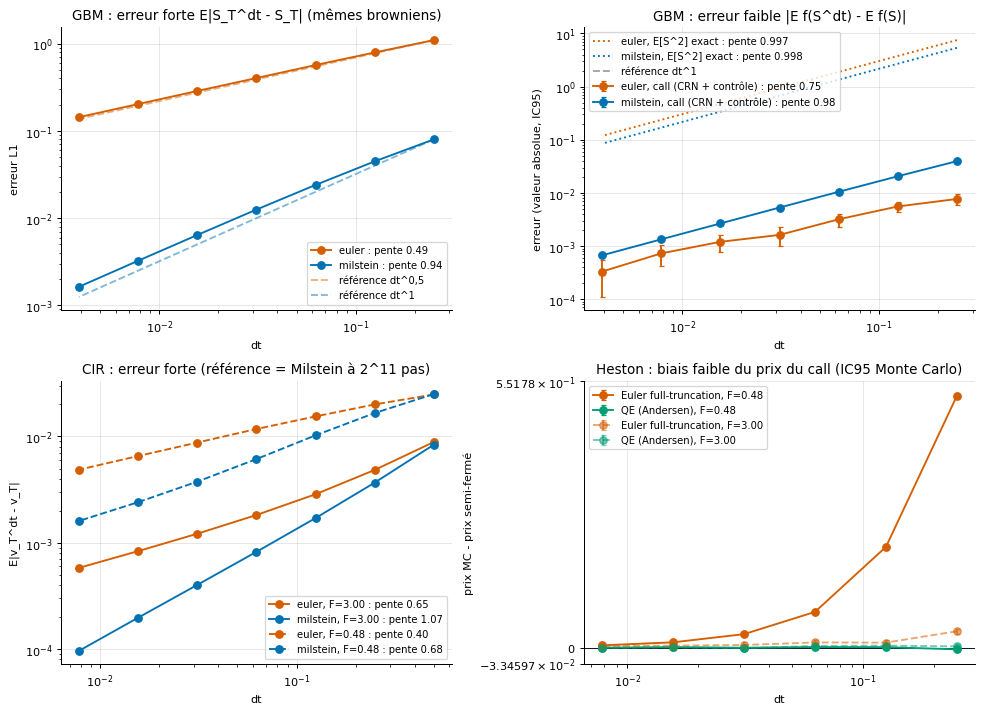

In [3]:
montrer("Q1", b)

In [4]:
lire("Q1", b)

- GBM, erreur forte (même brownien) : Euler en dt^0,49 [0,49 ; 0,49] (théorie 1/2) ; Milstein en dt^1,00 en L2 et dt^0,94 en L1 (théorie 1 ;
  la pente locale L1 vaut 0,99 aux pas les plus fins).
- GBM, erreur faible : Euler 0,72 ± 0,09 (call, bruité), Milstein 0,98 ; sans bruit (E[S^2] exact) 0,997 et 0,998 : ordre faible 1 pour les
  deux.
- CIR : les ordres du théorème exigent Feller. Feller respecté (F = 3,0) : Euler 0,65, Milstein 1,07 ; Feller violé (F = 0,48, paramètres du
  projet) : Euler 0,40, Milstein 0,68.
- Heston, biais faible du prix : Euler full-truncation 0,522 à 4 pas -> 0,028 à 32 pas -> 0,004 ± 0,002 à 128 pas ; QE : -0,004 à 4 pas,
  compatible avec 0 (chi2 p = 0,30), erreur-type 0,002.


**Conclusion.**

- GBM : l'erreur forte d'Euler suit bien $\Delta t^{1/2}$ et celle de Milstein $\Delta t^{1}$ (en $L^2$ ; en $L^1$ la pente globale est un peu sous 1 mais la pente *locale* aux pas les plus fins retrouve 1 : effet de préfacteur, pas de défaut du schéma).
- Erreur faible : la mesure sur le prix d'un call est **bruitée** pour Euler (la pente est loin de 1 avec un grand intervalle) ; le même calcul **sans bruit**, sur le moment exact $\mathbb{E}[S_T^2]$, donne l'ordre 1 pour les deux schémas, conforme au théorème. L'écart est un problème de mesure, pas de théorie.
- CIR : **le théorème n'est pas violé, il n'est pas applicable** hors Feller. Avec les paramètres du projet ($F = 0{,}48 < 1$) les pentes tombent nettement sous les valeurs théoriques (Euler et Milstein), alors qu'elles sont proches de la théorie quand Feller est respecté.
- Heston : le biais d'Euler full-truncation décroît avec le pas mais il est encore visible à 32 pas, le QE est compatible avec 0 dès 4 pas. C'est la raison pour laquelle le reste du labo utilise QE.

In [5]:
g, ci, h = c["gbm"], c["cir"], c["heston"]["feller_viole"]
assert abs(g["euler"]["fort_l1"]["pente"] - 0.5) < 0.05, "ordre fort d'Euler != 1/2"
assert 0.9 < g["milstein"]["fort_l2"]["pente"] < 1.1, "ordre fort L2 de Milstein != 1"
assert all(0.95 < g[s]["faible_x2_exact"]["pente"] < 1.05 for s in ("euler", "milstein")), "ordre faible sans bruit != 1"
assert ci["feller_viole"]["euler"]["pente"] < ci["feller_respecte"]["euler"]["pente"] - 0.1, "Feller n'aide pas Euler ?"
assert ci["feller_viole"]["milstein"]["pente"] < 0.9 < ci["feller_respecte"]["milstein"]["pente"], "Milstein CIR hors Feller"
assert h["qe"]["p_chi2_zero"] > 0.01, "QE biaisé ?"
assert abs(h["euler_ft"]["biais"][0]) > 10 * abs(h["qe"]["biais"][0]), "Euler-FT pas plus biaisé que QE ?"
print("Q1 : affirmations de la conclusion vérifiées")

Q1 : affirmations de la conclusion vérifiées


## Q2 · MLMC avec Milstein : le théorème de Giles

**Question.** Milstein rend-il le MLMC en $O(\varepsilon^{-2})$ ? Que valent $\alpha$, $\beta$, $\gamma$ mesurés, et quel gain de coût ?

**Intuition.** Le Monte Carlo multi-niveaux écrit $\mathbb{E}[P_L] = \mathbb{E}[P_0] + \sum_{l=1}^{L} \mathbb{E}[P_l - P_{l-1}]$. Chaque correction est calculée avec *le même brownien* sur deux grilles
consécutives : plus le schéma est précis fortement, plus la correction est petite et moins il faut de chemins aux niveaux chers. Avec Euler la variance de la correction décroît comme $h_l$ ($\beta = 1$), avec Milstein comme $h_l^2$ ($\beta = 2$).

**Théorème** (Giles 2008). Si $|\mathbb{E}[P_l - P]| \le c_1 2^{-\alpha l}$ avec $\alpha \ge \tfrac12\min(\beta,\gamma)$, $\;V_l \le c_2 2^{-\beta l}$ et $C_l \le c_3 2^{\gamma l}$, alors le coût pour atteindre une erreur quadratique moyenne $\varepsilon$ est
$$C \;=\; \begin{cases} O(\varepsilon^{-2}) & \beta > \gamma,\\ O\big(\varepsilon^{-2}(\log \varepsilon)^2\big) & \beta = \gamma,\\ O\big(\varepsilon^{-2-(\gamma-\beta)/\alpha}\big) & \beta < \gamma.\end{cases}$$
Ici $\gamma = 1$ (le coût d'un niveau est proportionnel au nombre de pas).

**Ce qu'on attend.** GBM : Euler $\beta = 1 = \gamma$ (coût en $\varepsilon^{-2}\log^2\varepsilon$), Milstein $\beta = 2 > \gamma$ ($\varepsilon^{-2}$ pur). Heston : $\beta = 2$ exige un bruit commutatif ($\rho \to -1$) et Feller ; sinon le terme d'aire de Lévy, omis par Milstein, limite $\beta$.

**Expérience.** Exposants $\alpha, \beta$ mesurés par régression sur $10^5$ chemins par niveau avec intervalles de confiance, puis coût total mesuré pour $\varepsilon \in \{0{,}05 \ldots 0{,}002\}$ ; Heston avec trois jeux de paramètres.

In [6]:
b = lancer("Q2")
c = b["chiffres"]

Q2 calculé en 46 s (graines fixées)


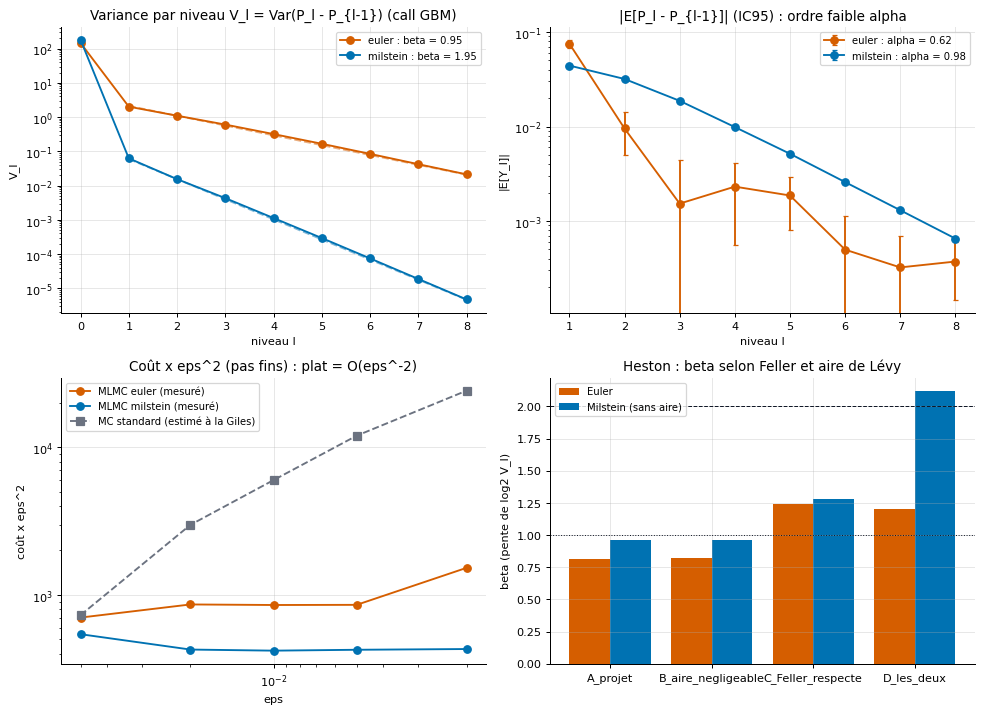

In [7]:
montrer("Q2", b)

In [8]:
lire("Q2", b)

- beta (variance par niveau, V_l ~ 2^(-beta l)) : Euler 0,95 [0,93 ; 0,98], Milstein 1,95 [1,92 ; 1,98] (théorie 1 et 2) ; alpha (ordre
  faible) : Euler 0,62 [0,32 ; 0,93], Milstein 0,98 [0,98 ; 0,98] ; gamma = 1 (pas fins).
- Giles : Euler beta ~ gamma donne eps^-2 (log eps)^2 ; Milstein beta > gamma donne eps^-2. Coût mesuré en eps^-x : x = 2,20 [1,98 ; 2,43]
  (Euler), 1,94 [1,82 ; 2,06] (Milstein), 3,08 pour le MC standard.
- Gain de coût de Milstein sur Euler (pas fins) : x1,3 à eps = 0.05 -> x3,6 à eps = 0.002 (coût x eps^2 : Euler 1526, Milstein 429) ; la
  croissance en log^2 d'Euler est masquée par le niveau 0 sur cette plage.
- Heston : beta passe de 0,81 (Euler) à 0,96 (Milstein) sur le cas du projet, mais atteint 2,12 [1,99 ; 2,24] seulement si Feller est
  respecté ET si l'aire de Lévy est négligeable (rho -> -1).


**Conclusion.** Le théorème est confirmé sur le GBM : $\beta$ passe d'environ 1 (Euler) à environ 2 (Milstein), et l'exposant du coût en $\varepsilon^{-x}$ passe de $x > 2$ à $x \approx 2$ (contre environ 3 pour le Monte Carlo standard).
Le gain de Milstein sur Euler **croît** quand $\varepsilon$ diminue, comme attendu. Deux nuances honnêtes : (i) le facteur $\log^2\varepsilon$ d'Euler est largement masqué par le niveau 0 sur cette plage d'$\varepsilon$, donc l'exposant mesuré pour Euler est « entre » 2 et 2,4 plutôt qu'exactement 2 ;
(ii) **sur Heston avec les paramètres du projet, Milstein n'atteint pas $\beta = 2$** : il n'arrive qu'à environ 1 (Euler : 0,8), et ne retrouve $\beta \approx 2$ que dans le cas favorable (Feller respecté et $\rho \to -1$). Ce n'est pas une contradiction du théorème de Giles, c'est la limite attendue d'un Milstein sans aire de Lévy.

In [9]:
g, hs = c["gbm"], c["heston"]
assert g["euler"]["beta"] < 1.2 and g["milstein"]["beta"] > 1.7, "beta mesurés"
assert g["milstein"]["cout"]["pente_cout"] < g["euler"]["cout"]["pente_cout"] < g["euler"]["cout"]["pente_cout_standard"], "ordre des coûts"
assert g["milstein"]["cout"]["pente_cout"] < 2.1, "Milstein pas en eps^-2"
assert c["gain_cout_milstein_sur_euler"][-1] > c["gain_cout_milstein_sur_euler"][0] > 1, "le gain doit croître quand eps diminue"
assert hs["A_projet (Feller violé, rho=-0,7)"]["milstein"]["beta"] < 1.3, "Heston du projet : beta < 2 attendu"
assert hs["D_les_deux (xi=0,3, rho=-0,999)"]["milstein"]["beta"] > 1.7, "cas favorable : beta ~ 2 attendu"
print("Q2 : affirmations de la conclusion vérifiées")

Q2 : affirmations de la conclusion vérifiées


## Q3 · Pourquoi le pont brownien (et l'ACP) aident le QMC : la dimension effective

**Question.** Pour une option asiatique à $d$ dates, le QMC de Sobol converge beaucoup mieux avec la construction en pont brownien qu'avec la construction incrémentale.
Pourquoi, et peut-on faire encore mieux (ACP) ? Que mesure la « dimension effective » ?

**Intuition.** Une suite de Sobol est très régulière dans ses *premières* coordonnées et dégrade ensuite. Le prix est une fonction $f(Z_1,\dots,Z_d)$ de $d$ normales ;
la construction du brownien décide *quelles* coordonnées portent la variance. Incrémentale : $W_{t_j} = \sqrt{\Delta t}\sum_{i\le j} Z_i$, toutes les coordonnées comptent autant. Pont : $Z_1$ fixe $W_T$, $Z_2$ le milieu, etc. : les gros mouvements viennent en premier.
ACP : on diagonalise $\operatorname{Cov}(W) = \Delta t\,\min(i,j) = V\Lambda V^\top$ et on pose $W = V\Lambda^{1/2} Z$ avec les valeurs propres triées : la première coordonnée porte la plus grande part possible de variance.

**Théorème.** (a) Décomposition ANOVA de Hoeffding–Sobol : $f = \sum_{u} f_u$, $\operatorname{Var} f = \sum_u \sigma_u^2$. La variance expliquée par les $k$ premières coordonnées est l'indice de Sobol *fermé*
$$\underline{S}_{\{1..k\}} \;=\; \frac{\operatorname{Var}\big(\mathbb{E}[f \mid Z_1,\dots,Z_k]\big)}{\operatorname{Var} f}.$$
La dimension effective de troncature (Caflisch–Morokoff–Owen) est le plus petit $k$ tel que cet indice atteigne $99\,\%$.
(b) Koksma–Hlawka : $|I_N - I| \le V_{HK}(f)\,D^*_N$ avec $D^*_N = O\big((\log N)^s/N\big)$ en dimension $s$ : si $f$ est presque entièrement portée par $s$ coordonnées de tête avec $s$ petit, l'erreur suit la discrépance de cette projection et non celle de la dimension $d$.

**Ce qu'on attend.** Variance expliquée par la 1ʳᵉ coordonnée : ACP > pont > incrémental ; RMSE du QMC dans le même ordre ; pente $\to -1$ quand la dimension effective est petite.

**Expérience.** Indices fermés par *pick-freeze* (estimateur de Janon–Monod–Nodet) sur $d \in \{16, 32, 64\}$, puis RMSE du QMC randomisé (24 brouillages) pour $N = 2^6 \ldots 2^{14}$.

In [10]:
b = lancer("Q3")
c = b["chiffres"]

Q3 calculé en 48 s (graines fixées)


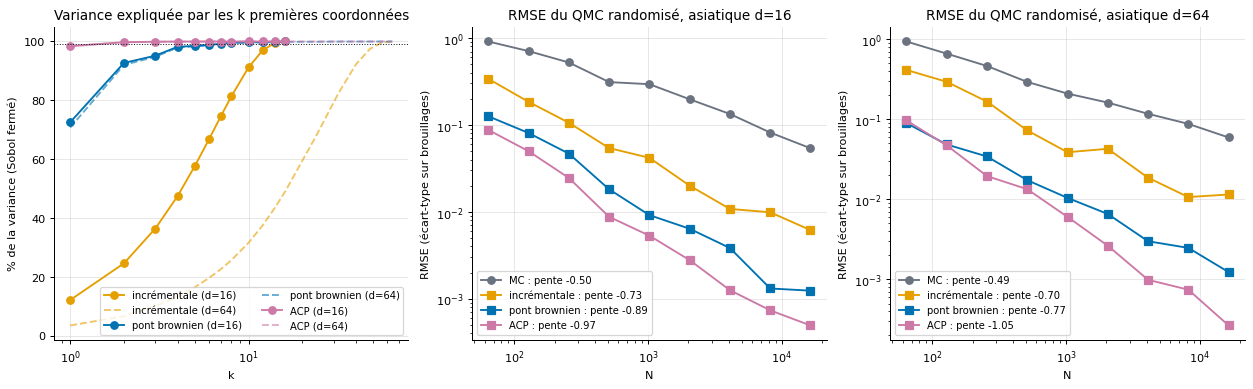

In [11]:
montrer("Q3", b)

In [12]:
lire("Q3", b)

- Variance expliquée par la 1re coordonnée (d = 16) : 12,1 % (incrémentale), 72,6 % (pont), 98,4 % (ACP) ; par les 4 premières : 47,4 / 98,2
  / 100,0 %.
- Dimension effective de troncature à 99 % : 14 / 7 / 2 à d = 16, 56 / 7 / 2 à d = 64 : seule la construction incrémentale en dépend
  (résolution 8 au-delà de k = 16).
- RMSE à N = 2^14 (d = 16) : MC 5.4e-02, incrémentale 6.2e-03, pont 1.2e-03, ACP 4.9e-04 (pentes -0,50 / -0,73 / -0,89 / -0,97).
- Koksma-Hlawka : l'erreur suit la discrépance de la projection qui porte la variance ; gain de l'ACP sur le pont : x2,5 à d = 16, x4,6 à d
  = 64.


**Conclusion.** L'ordre prédit est observé partout : la part de variance portée par la première coordonnée passe d'environ 12 % (incrémental) à environ 73 % (pont) puis 98 % (ACP) à $d = 16$, la dimension effective de troncature tombe de 14 à 7 puis 2,
et la RMSE suit : l'ACP gagne un facteur 2,5 sur le pont à $d = 16$ et davantage à $d = 64$. Deux remarques : (i) **seule la construction incrémentale voit sa dimension effective dépendre de $d$** (56 à $d = 64$), le pont (7) et l'ACP (2) restent stables, ce qui explique leur avantage croissant avec $d$ ;
(ii) la pente ACP (environ $-0{,}97$) n'atteint pas exactement $-1$ : le coude du payoff $\max(\cdot,0)$ coûte un facteur logarithmique, ce que Koksma–Hlawka n'exclut pas.

In [13]:
bl = c["blocs"]; b16 = bl["16"]; bmax = bl[str(max(int(d) for d in bl))]
def part(b, k, kk=1): return b[k]["indice"][b[k]["ks"].index(kk)]
assert part(b16, "acp") > part(b16, "pont") > part(b16, "incrementale"), "variance de la 1re coordonnée"
assert b16["acp"]["dim_troncature_99"] < b16["pont"]["dim_troncature_99"] < b16["incrementale"]["dim_troncature_99"], "dimension effective"
assert bmax["incrementale"]["dim_troncature_99"] > 3 * b16["incrementale"]["dim_troncature_99"], "l'incrémentale devrait dépendre de d"
assert bmax["pont"]["dim_troncature_99"] == b16["pont"]["dim_troncature_99"], "le pont ne devrait pas dépendre de d"
r = {k: b16[k]["rmse"]["rmse"][-1] for k in ("incrementale", "pont", "acp")}
assert b16["mc"]["rmse"][-1] > r["incrementale"] > r["pont"] > r["acp"], "ordre des RMSE"
assert b16["acp"]["rmse"]["pente"] < -0.9, "pente ACP"
print("Q3 : affirmations de la conclusion vérifiées")

Q3 : affirmations de la conclusion vérifiées


## Q4 · Stratification (proportionnelle, Neyman) et hypercube latin

**Question.** Combien de variance gagne-t-on en stratifiant le brownien terminal, avec une allocation proportionnelle ou de Neyman, ou avec un hypercube latin (LHS) ? La théorie prédit-elle le gain mesuré ?

**Intuition.** Stratifier, c'est forcer l'échantillon à visiter tous les « quartiers » de $(0,1)$ au lieu de laisser le hasard en oublier. La variance qui reste est celle *à l'intérieur* des strates ; celle *entre* strates disparaît.
Neyman va plus loin : il met plus de points là où la fonction varie le plus (là où $\sigma_h$ est grand). Le LHS stratifie *chaque coordonnée* en même temps, mais ne retire que la partie additive de $f$.

**Théorème.** Avec $H$ strates de probabilités $p_h$, de moyennes $\mu_h$ et d'écarts-types $\sigma_h$ : $\operatorname{Var}(I_{\text{strat}}) = \sum_h p_h^2\sigma_h^2/n_h$.
Allocation proportionnelle ($n_h = n p_h$) : $\dfrac{1}{n}\sum_h p_h\sigma_h^2 \le \dfrac{\sigma^2}{n}$ (loi de la variance totale). Allocation de Neyman ($n_h \propto p_h\sigma_h$) : $\dfrac1n\Big(\sum_h p_h\sigma_h\Big)^2 \le \dfrac1n\sum_h p_h\sigma_h^2$ (Cauchy–Schwarz).
LHS (Stein 1987) : variance asymptotique $\dfrac1n\Big(\sigma^2 - \sum_{j}\sigma_j^2\Big)$, où $\sigma_j^2 = \operatorname{Var}\,\mathbb{E}[f \mid U_j]$ : le gain est $1/(1-\sum_j S_j)$, avec $S_j$ les indices de Sobol d'ordre 1.

**Ce qu'on attend.** Facteurs mesurés égaux aux facteurs théoriques à la précision de l'expérience ; Neyman $\gg$ proportionnelle quand les $\sigma_h$ sont très inégaux ; gain LHS $= 1/(1-\sum_j S_j)$.

**Expérience.** 800 répétitions indépendantes de chaque estimateur à $n = 4096$ ; $\mu_h$ et $\sigma_h$ exacts par quadrature pour la théorie ; allocation de Neyman avec $\sigma_h$ connus (« oracle ») et avec un pilote.

In [14]:
b = lancer("Q4")
c = b["chiffres"]

Q4 calculé en 46 s (graines fixées)


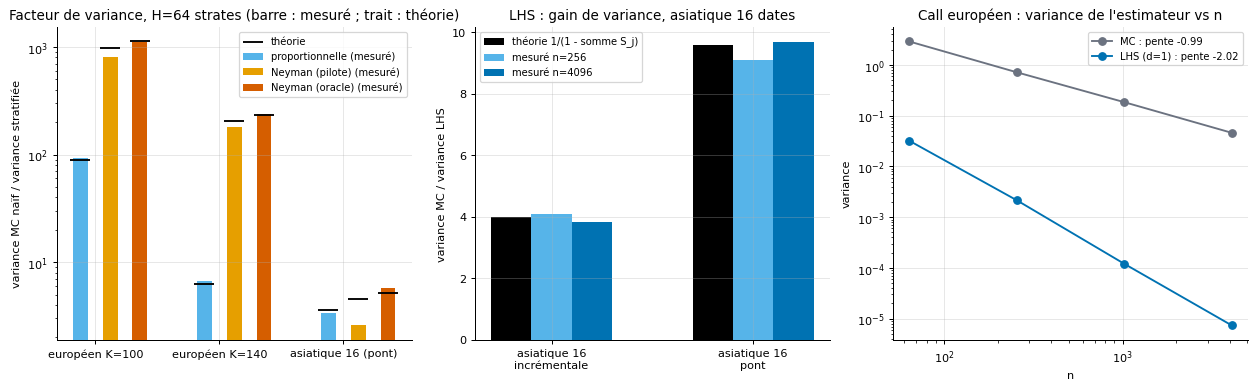

In [15]:
montrer("Q4", b)

In [16]:
lire("Q4", b)

- Stratification de la normale terminale, H = 64 (n = 4096), européen ATM : x92 mesuré (proportionnelle) contre x89 prédit par sigma^2 /
  somme(p_h sigma_h^2) ; Neyman avec sigma_h connus x1110 (théorie x1125). Précision de chaque facteur mesuré : ~4 %.
- Call OTM K = 140 (sigma_h très inégaux) : proportionnelle x6,7, Neyman x237 (oracle) et x180 (pilote n/8). Asiatique 16 dates (Z_1 du pont
  stratifiée) : x3,4 / x2,6 (pilote) / x5,7 (oracle), théorie 3,6 / 5,2 (proportionnelle / oracle).
- LHS (Stein) : somme des indices de Sobol d'ordre 1 = 0,749 (incrémentale), 0,896 (pont) -> gain asymptotique prédit x4,0 / x9,6 ; mesuré à
  n = 4096 : x3,8 / x9,7.
- Dimension 1 : le LHS est une stratification à n strates, variance en n^-2,02 contre n^-0,99 pour le MC.


**Conclusion.** Les facteurs de variance mesurés collent aux facteurs prédits par les formules, à la précision statistique de l'expérience (environ 4 % par facteur) : la théorie fonctionne comme **outil de prévision**, pas seulement comme borne.
Neyman ne bat nettement la proportionnelle que lorsque les $\sigma_h$ sont inégaux (call très hors de la monnaie) ; l'allocation *oracle* (qui connaît les $\sigma_h$) est une borne inaccessible, le **pilote** en récupère l'essentiel mais pas tout.
Pour le LHS, le gain asymptotique prédit par la somme des indices de Sobol d'ordre 1 est retrouvé : environ 4 pour la construction incrémentale (environ 75 % de la variance est additive) et environ 10 pour le pont (environ 90 %). En dimension 1 le LHS *est* une stratification à $n$ strates : variance en $n^{-2}$ au lieu de $n^{-1}$.

In [17]:
st, lh = c["strates"], c["lhs"]
e1, e2, a = st["europeen_K100"]["64"], st["europeen_K140"]["64"], st["asiatique_16_pont"]["64"]
for e in (e1, e2, a):
    assert 0.8 < e["mesure"]["facteur_prop"] / e["theorie"]["facteur_prop"] < 1.25, "proportionnelle : mesure != théorie"
    assert e["mesure"]["facteur_neyman_oracle"] > e["mesure"]["facteur_prop"], "Neyman oracle >= proportionnelle"
assert e2["mesure"]["facteur_neyman_pilote"] > 5 * e2["mesure"]["facteur_prop"], "sigma_h inégaux : Neyman doit dominer"
for nom in ("asiatique_16_incrementale", "asiatique_16_pont"):
    x = lh[nom]
    assert 0.8 < x["n"]["4096"]["gain_mesure"] / x["gain_asymptotique_theorique"] < 1.25, f"gain LHS {nom}"
assert lh["asiatique_16_pont"]["somme_S1"] > lh["asiatique_16_incrementale"]["somme_S1"], "additivité du pont"
assert lh["europeen_d1"]["pente_var_lhs"] < -1.8 and -1.2 < lh["europeen_d1"]["pente_var_mc"] < -0.8, "LHS 1D = n^-2"
print("Q4 : affirmations de la conclusion vérifiées")

Q4 : affirmations de la conclusion vérifiées


## Q5 · Importance sampling optimal et entropie croisée

**Question.** Pour estimer $\mathbb{E}[f(Z)]$ quand $f$ ne « voit » qu'une queue de la gaussienne (call très hors de la monnaie, défaut rare), quelle dérive $\mu$ de Girsanov minimise la variance, et la méthode d'entropie croisée la retrouve-t-elle ?

**Intuition.** On tire $Y \sim \mathcal{N}(\mu,1)$ au lieu de $\mathcal{N}(0,1)$ pour tomber plus souvent là où $f \neq 0$, et on corrige par le rapport de vraisemblance $w(Y) = e^{-\mu Y + \mu^2/2}$ : l'estimateur reste sans biais pour tout $\mu$. Pousser trop peu ne sert à rien ;
pousser trop loin rend les poids très inégaux. Il y a un $\mu$ optimal.

**Théorème.** La variance par tirage vaut $M(\mu) - I^2$ avec le second moment
$$M(\mu) = \mathbb{E}\big[f(Z)^2\, e^{-\mu Z + \mu^2/2}\big],$$
**convexe** en $\mu$ (somme d'exponentielles à coefficients positifs), donc de minimum unique $\mu^*$. L'entropie croisée vise la loi de variance nulle $g^* \propto f\varphi$ : elle choisit $\mu_{CE} = \mathbb{E}[f(Z)Z]/\mathbb{E}[f(Z)]$ (la moyenne de $g^*$).
Grandes déviations : pour $\{Z > a\}$, $M(\mu) = e^{\mu^2}\,\mathbb{P}(Z > a+\mu)$, $\mu^* \sim a$ et $\ln M(\mu^*) / (2\ln \mathbb{P}(Z>a)) \to 1$ (efficacité logarithmique).

**Ce qu'on attend.** $\mu^*$ proche mais différent du choix naïf $\mu = z_K$ (strike) ; $\mu_{CE}$ proche de $\mu^*$ mais pas identique (l'entropie croisée minimise une divergence de Kullback–Leibler, pas la variance) ; la variance empirique retrouve $M(\mu) - I^2$ ; le rapport logarithmique tend vers 1.

**Expérience.** Call $K = 180$ et défaut rare d'un portefeuille de crédit à un facteur (Vasicek) ; $M(\mu)$ par quadrature adaptative ; entropie croisée itérative (8 itérations de 20 000 tirages, 10 graines) ; variance empirique sur 400 000 tirages.

In [18]:
b = lancer("Q5")
c = b["chiffres"]

Q5 calculé en 2 s (graines fixées)


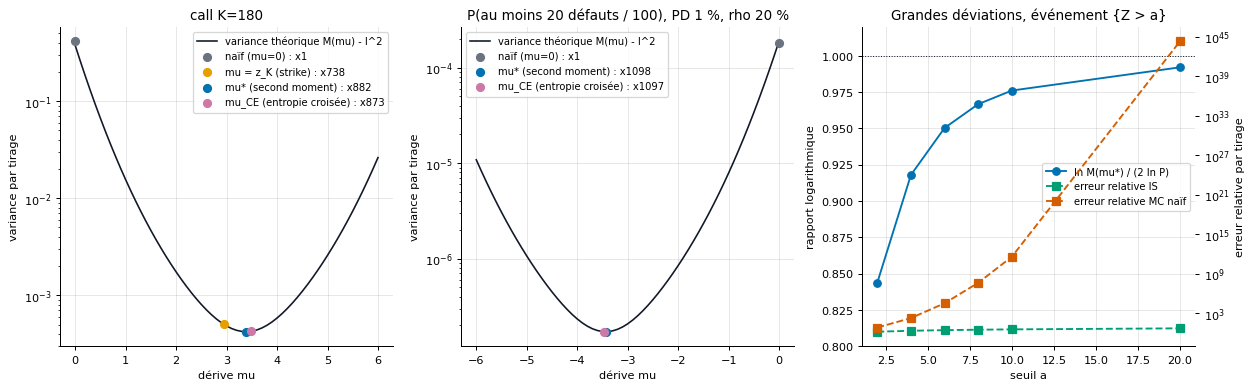

In [19]:
montrer("Q5", b)

In [20]:
lire("Q5", b)

- Call K = 180 : le second moment M(mu) est convexe ; mu* = 3,386 (variance divisée par 882), contre mu = z_K = 2,939 (x738, dérive centrée
  sur le strike) et mu_CE = 3,491 (x873). L'entropie croisée par 8 itérations de 20 000 tirages donne mu = 3,492 ± 0,003 (10 graines).
- Défaut rare (au moins 20 défauts sur 100, P = 4.04e-04) : mu* = -3,436, mu_CE = -3,465, variance divisée par 1098 (CE : 1097).
- La variance empirique (n = 400000) retrouve M(mu) - I^2 à 0,3 % près sur les dérives d'importance.
- Grandes déviations : ln M(mu*) / (2 ln P) = 0,844 (a = 2) -> 0,950 (a = 6) -> 0,992 (a = 20) ; l'erreur relative de l'IS ne vaut que 4,9 à
  a = 20 (MC naïf : 1.9e+44).


**Conclusion.** Le minimum de $M(\mu)$ existe, est unique, et donne le meilleur facteur de réduction de variance ; l'entropie croisée, obtenue par simple simulation itérative (sans connaître $M$), retrouve une dérive très proche et un facteur presque identique (par construction elle ne peut pas faire *mieux* que $\mu^*$ en variance).
Le choix « naïf » $\mu = z_K$ est correct en ordre de grandeur mais laisse une partie du gain sur la table. Le rapport $\ln M(\mu^*)/(2\ln P)$ tend bien vers 1 **mais lentement** (environ 0,84 à $a = 2$, 0,99 à $a = 20$) : l'efficacité logarithmique est asymptotique, pas immédiate. À $a = 20$ l'importance sampling a une erreur relative d'environ 5 contre $10^{44}$ pour le Monte Carlo naïf.

In [21]:
k, cr, le = c["cas"]["call_K180"], c["cas"]["credit"], c["efficacite_logarithmique"]
for cas in (k, cr):
    p = cas["points"]
    assert p["mu_star"]["facteur_variance"] >= p["mu_ce"]["facteur_variance"] * (1 - 1e-6), "mu* minimise la variance"
    assert p["mu_star"]["facteur_variance"] >= p["strike"]["facteur_variance"] * (1 - 1e-6) if "strike" in p else True
    ecart = max(abs(v["variance_empirique"] / v["variance_theorique"] - 1) for lib, v in p.items() if lib != "naif")
    assert ecart < 0.05, "variance empirique != M(mu) - I^2"
assert abs(np.mean(k["ce_mu_final"]) - k["points"]["mu_ce"]["mu"]) < 0.05, "l'entropie croisée doit converger vers mu_CE exact"
rap = [x["rapport_log"] for x in le]
assert all(np.diff(rap) > 0) and rap[-1] > 0.98 and rap[0] < 0.9, "efficacité logarithmique"
print("Q5 : affirmations de la conclusion vérifiées")

Q5 : affirmations de la conclusion vérifiées


## Q6 · Grecques par différentiation adjointe (AAD) codée à la main

**Question.** Peut-on obtenir *toutes* les grecques d'un payoff (delta, rho, un vega par date de fixing, sensibilité au strike) pour environ 3 à 4 fois le coût du prix, et sont-elles exactes ?

**Intuition.** Le bump-and-revalue recalcule le prix une fois (ou deux, en différence centrée) par paramètre : $m$ paramètres coûtent $2m$ évaluations. La dérivation en mode inverse (« adjointe ») fait **un seul** passage avant pour calculer le prix et **un seul** passage arrière
qui propage $\bar x = \partial P/\partial x$ de la sortie vers toutes les entrées : le coût du gradient ne dépend plus de $m$.

**Théorème** (principe du gradient bon marché, Griewank). Pour un programme de coût $\mathrm{TEMPS}\{F\}$ à $m$ entrées,
$$\mathrm{TEMPS}\{F,\nabla F\} \le \omega\,\mathrm{TEMPS}\{F\},\qquad \omega \approx 3\text{ à }4,\ \text{indépendant de } m.$$
Ici, sur la trajectoire $S_j = S_{j-1}e^{a_j}$, $a_j = (r - q - \sigma_j^2/2)\Delta t + \sigma_j\sqrt{\Delta t}\,Z_j$, on remonte : $\bar S_j = \partial_{S_j} g + \bar S_{j+1}S_{j+1}/S_j$, $\;\bar a_j = \bar S_j S_j$, $\;\bar\sigma_j = \bar a_j(-\sigma_j\Delta t + \sqrt{\Delta t}\,Z_j)$.

**Ce qu'on attend.** L'AAD égale le pathwise écrit à la main (même chemins) à l'arrondi près ; elle retrouve Black–Scholes (européen) et les différences finies de la formule fermée (asiatique géométrique) ; son coût relatif au prix reste à peu près constant quand $m$ grandit, alors que le bump-and-revalue croît comme $2m$.

**Expérience.** Exactitude sur 400 000 chemins, 12 dates ; coût mesuré pour $d \in \{8,16,32,64\}$ dates (donc $m = d + 3$ grecques), minimum de plusieurs répétitions. **Les temps dépendent de la machine.**

In [22]:
b = lancer("Q6")
c = b["chiffres"]

Q6 calculé en 26 s (graines fixées)


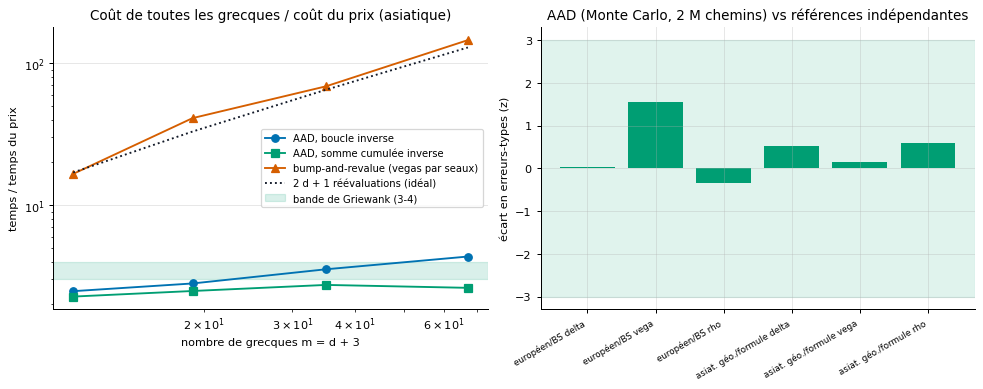

In [23]:
montrer("Q6", b)

In [24]:
lire("Q6", b)

- Exactitude : sur les mêmes chemins (n = 400000, 12 dates), l'AAD en mode inverse égale le pathwise écrit à la main à 6e-13 près en valeur
  absolue (grecques de l'ordre de 10 à 500) ; boucle et version vectorisée coïncident.
- Contre des références indépendantes : européen vs Black-Scholes z = 0,03 / 1,56 / -0,34 (delta / vega / rho) ; asiatique géométrique vs
  différences finies de la formule fermée z = 0,53 / 0,15 / 0,59.
- Coût relatif au prix (asiatique, 64 dates, 67 grecques dont 64 vegas par date) : AAD 4,3x (boucle) et 2,6x (vectorisé), contre 145x pour
  le seul bump-and-revalue des vegas (129 réévaluations).
- Le rapport AAD/prix reste dans 2,5-4,3x (boucle) quand m passe de 11 à 67 (Griewank : 3 à 4 en comptage d'opérations) ; accélération sur
  le bump : x33 (boucle) à x56 (vectorisé). Temps numpy : dépendent de la machine.


**Conclusion.** Exactitude : l'AAD codée à la main coïncide avec le pathwise à environ $10^{-12}$ près (valeur absolue, pour des grecques de l'ordre de 10 à 500), et les deux implémentations (boucle, vectorisée) sont identiques ; contre les références indépendantes les $z$-scores restent dans $\pm 2$.
Coût : la version vectorisée reste à environ 2 à 4 fois le prix quel que soit $m$ (de 11 à 67 grecques), conforme à Griewank ; la version en boucle peut monter un peu plus haut (2 à 5 fois selon la machine et l'exécution) à cause du surcoût d'interprétation et de la mémoire, pas parce que le principe est faux : le théorème porte sur le *nombre d'opérations*, pas sur les secondes.
Le bump-and-revalue des seuls vegas coûte de 17 à plus de 150 fois le prix (il croît comme $2m$) : l'AAD est de 7 à 60 fois plus rapide. **Une leçon de méthode** : une première exécution de ce bloc (machine très chargée) avait donné un coût AAD *inférieur* au prix, ce qui est impossible ; la cause était un chronométrage bruité et une référence « prix » alourdie par le calcul inutile des adjoints. Le prix de référence est maintenant minimal et on prend le minimum de plusieurs répétitions.

In [25]:
ex = c["exactitude"]
assert max(max(v["max_abs_aad_vs_pathwise"].values()) for v in ex.values()) < 1e-9, "AAD != pathwise"
assert all(abs(x["z"]) < 4 for x in (*c["vs_black_scholes_europeen"].values(), *c["vs_geometrique_ferme"].values())), "références"
co = c["cout"]
assert all(x["aad_vectorise"] >= 1.0 and x["aad_boucle"] >= 1.0 for x in co), "le gradient ne peut pas coûter moins que le prix"
assert max(x["aad_vectorise"] for x in co) < 5, "cout vectorisé"
assert co[-1]["bump_seaux"] > 10 * co[-1]["aad_vectorise"], "bump >> AAD"
assert co[-1]["bump_seaux"] / co[0]["bump_seaux"] > 4, "le bump doit croître avec m"
print("Q6 : affirmations de la conclusion vérifiées")

Q6 : affirmations de la conclusion vérifiées


## Q7 · Puissance des backtests de VaR et contributions d'Euler à l'ES

**Question.** (a) Combien d'années de backtest faut-il pour détecter un modèle de VaR 99 % qui dépasse 2 % du temps au lieu de 1 % ? Le test de Christoffersen voit-il ce que Kupiec ne voit pas ?
(b) D'où vient l'Expected Shortfall d'un portefeuille, ligne par ligne ?

**Intuition.** Un test de modèle a une *taille* (probabilité de rejeter à tort un bon modèle, visée 5 %) et une *puissance* (probabilité de rejeter un mauvais modèle). Les exceptions de VaR sont **rares** (2,5 par an à 1 %), donc la loi du $\chi^2$ est mauvaise à horizon court et la puissance est faible.
Kupiec ne regarde que le *nombre* d'exceptions ; Christoffersen regarde aussi leur *enchaînement* (les exceptions groupées en crise). Pour (b), l'ES est la moyenne des pertes dans la queue : chaque ligne y contribue pour sa perte moyenne *quand le portefeuille va mal*.

**Théorème.** Puissance $= \mathbb{P}\big(LR > \chi^2_{1-a}\ \big|\ H_1\big)$ avec, sous $H_1$, le nombre d'exceptions $x \sim \mathrm{Binomiale}(T, p_1)$ (calculable exactement). Théorème d'Euler : si $F$ est homogène de degré 1, $F(w) = \sum_i w_i\,\partial F/\partial w_i$. Pour l'ES (Tasche),
$$w_i\frac{\partial \mathrm{ES}}{\partial w_i} \;=\; \mathbb{E}\big[\text{perte de la ligne } i \ \big|\ L \ge \mathrm{VaR}\big],\qquad \sum_i w_i\frac{\partial \mathrm{ES}}{\partial w_i} = \mathrm{ES}.$$

**Ce qu'on attend.** Puissance de Kupiec d'environ 25 % à 1 an, plus de 80 % vers 4-5 ans ; Christoffersen rejette les exceptions groupées de bon taux que Kupiec laisse passer ; somme des contributions $=$ ES à la précision machine ; une ligne qui couvre le portefeuille a une contribution négative.

**Expérience.** Puissance exacte (énumération binomiale) et par simulation ; chaînes de Markov pour les exceptions groupées ; ES FHS 97,5 % du 9 mars 2020 sur le portefeuille réel du volet risque (si les données sont présentes, variable `UNIVERS_DIR`).

In [26]:
b = lancer("Q7")
c = b["chiffres"]

Q7 calculé en 12 s (graines fixées)


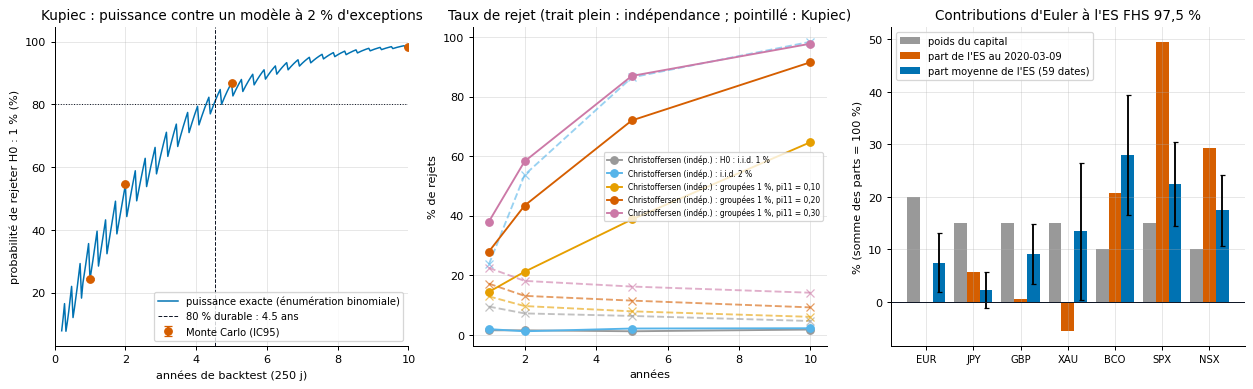

In [27]:
montrer("Q7", b)

In [28]:
lire("Q7", b)

- Kupiec, modèle à 2 % au lieu de 1 % : puissance 24 % à 1 an, 54 % à 2 ans, 87 % à 5 ans, 98 % à 10 ans ; 80 % de puissance durable après
  1130 jours (4,5 ans ; formule normale 3,9 ans). La taille réelle du test vaut 9,5 % à 1 an (pas 5 %).
- Bâle : un modèle à 2 % est en zone verte 44 % du temps sur 250 jours. Exceptions groupées de taux correct 1 % (pi11 = 0,20) :
  Christoffersen (indépendance) rejette 28 / 43 / 72 / 92 % à 1/2/5/10 ans, Kupiec seulement 9 % à 10 ans.
- ES FHS 97,5 % au 9 mars 2020 : 247 659 EUR ; somme des contributions d'Euler = ES à 2e-16 près ; dérivées numériques w_i dES/dw_i =
  contributions à 1e-10 ; ES(2w)/ES(w) = 2.000000.
- Parts de l'ES (poids du capital) : SPX 50 % (15 %), NSX 29 % (10 %), BCO 21 % (10 %), XAU -6 % (15 %) ; moyenne sur 59 dates : SPX 22 %,
  NSX 17 %, BCO 28 %, XAU 13 %.


**Conclusion.** (a) Un modèle qui se trompe d'un facteur 2 sur le taux d'exceptions n'est détecté qu'une fois sur quatre après un an de backtest et il faut **plus de quatre ans** pour atteindre durablement 80 % de puissance : la formule normale de dimensionnement (environ 3,9 ans) est **trop optimiste** car la statistique est discrète et les événements rares.
La taille réelle du test à un an est d'environ 9,5 %, pas 5 % : un bon modèle est rejeté presque deux fois trop souvent. Christoffersen détecte les exceptions groupées de taux correct que Kupiec ne voit presque jamais : les deux tests ne sont pas substituables.
(b) La somme des contributions d'Euler reproduit l'ES à la précision machine et coïncide avec les dérivées numériques ; la ligne d'or a une contribution *négative* le 9 mars 2020 (elle couvrait), l'indice actions pèse bien plus dans l'ES que dans le capital.

In [29]:
kp, ch = c["kupiec"]["points"], c["christoffersen"]["groupées 1 %, pi11 = 0,20"]
assert kp["250"]["puissance_exacte"] < 0.5 and kp["2500"]["puissance_exacte"] > 0.95, "puissance de Kupiec"
assert c["kupiec"]["T_80"] > c["kupiec"]["T_80_formule_normale"], "formule normale optimiste"
assert kp["250"]["taille_reelle"] > 0.07, "taille réelle à 1 an > 5 %"
assert ch["2500"]["ind"] > 0.8 and ch["2500"]["kupiec"] < 0.2, "Christoffersen voit les clusters, pas Kupiec"
es = c["es_euler"]
if "donnees_absentes" in es:
    print("Q7 (b) : données de marché absentes (définir UNIVERS_DIR), partie ES non vérifiée")
else:
    e9 = es["jour_2020_03_09"]
    assert e9["ecart_relatif_somme"] < 1e-9 and e9["ecart_relatif_euler_derivees"] < 1e-6, "Euler"
    assert min(e9["parts"].values()) < 0 < max(e9["parts"].values()), "une ligne couvre"
    assert e9["parts"]["SPXUSD"] > e9["poids"]["SPXUSD"], "SPX pèse plus dans l'ES que dans le capital"
print("Q7 : affirmations de la conclusion vérifiées")

Q7 : affirmations de la conclusion vérifiées


## Q8 · Bonus : la condition de Feller et la fraction de pas tronqués

**Question.** Que vaut la condition de Feller $F = 2\kappa\theta/\xi^2 \ge 1$ pour la discrétisation : quelle fraction de pas Euler full-truncation doit-il corriger (variance négative ramenée à 0) selon $F$ ?

**Intuition.** Le processus CIR $dv = \kappa(\theta-v)dt + \xi\sqrt v\,dW$ ne touche jamais 0 si le rappel vers $\theta$ domine la diffusion, c'est-à-dire si $F \ge 1$. Le schéma discret, lui, peut sauter sous 0 : il faut alors tronquer.
Plus $F$ est petit, plus le processus passe de temps près de 0 et plus la troncature est fréquente.

**Théorème** (Feller 1951). Le bord 0 est inatteignable ssi $F \ge 1$. La loi stationnaire est $\Gamma\big(F,\ \xi^2/(2\kappa)\big)$, donc $\mathbb{P}(v < \varepsilon) \sim \varepsilon^{F}$. Euler tronque quand $v_n + \xi\sqrt{v_n\Delta t}\,Z < 0$, soit avec une probabilité en $\Delta t^{F}$.

**Ce qu'on attend.** Pente log-log de la fraction de pas tronqués en $\Delta t$ égale à $F$ ; troncature massive et biais de la moyenne de $v_T$ quand $F < 1$.

**Expérience.** $F \in \{0{,}25;\,0{,}5;\,1;\,2;\,4\}$ (le cas du projet vaut $0{,}48$), $200\,000$ chemins, pas de 8 à 256.

In [30]:
b = lancer("Q8")
c = b["chiffres"]

Q8 calculé en 18 s (graines fixées)


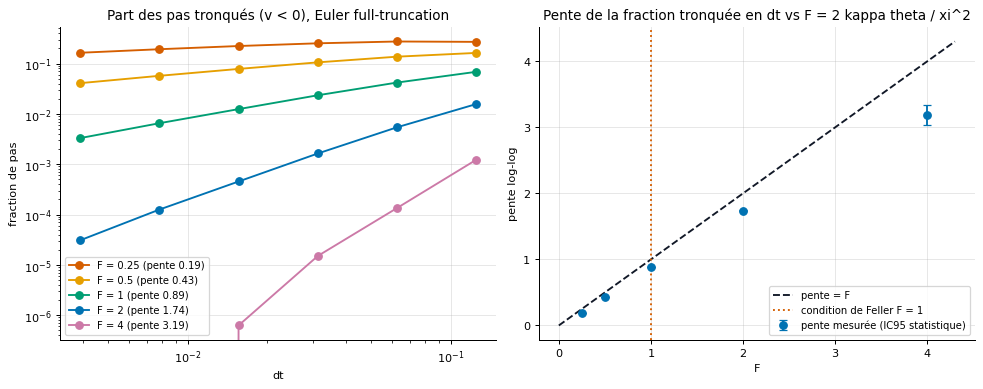

In [31]:
montrer("Q8", b)

In [32]:
lire("Q8", b)

- Pente log-log de la part des pas tronqués en dt : F = 0,25 -> 0,19 ; F = 0,50 -> 0,43 ; F = 1,00 -> 0,89 ; F = 2,00 -> 1,74 ; F = 4,00 ->
  3,19 (la pente croît avec F = 2 kappa theta / xi^2 et reste sous F : régime non asymptotique).
- À 16 pas, la troncature touche 27 % des pas pour F = 0,25, 14 % pour F = 0,5 (cas du projet : 0,48), 4,2 % pour F = 1, 0,013 % pour F = 4.
- Biais relatif de E[v_T^+] à 16 pas : 1,3 % (F = 0,5) contre 0,23 % (F = 4).


**Conclusion.** La fraction de pas tronqués décroît bien comme une puissance de $\Delta t$, et plus vite quand $F$ est grand : c'est le sens de la prédiction. **Mais la pente mesurée reste sous $F$** (par exemple environ 0,9 pour $F = 1$ et environ 3,2 pour $F = 4$) :
la loi $\Delta t^{F}$ est un résultat *asymptotique* ($\Delta t \to 0$) et nos pas ($\Delta t \ge 1/256$) sont dans le régime non asymptotique. Écart expliqué, pas masqué. En pratique avec les paramètres du projet ($F = 0{,}48$) environ un pas sur sept est tronqué à 16 pas, ce qui explique le biais visible d'Euler full-truncation sur Heston (Q1) et le choix de QE pour tout le reste du labo.

In [33]:
bl = c["blocs"]
cles = sorted(bl, key=lambda s: float(s))
pentes = [bl[s]["pente"] for s in cles]
assert all(np.diff(pentes) > 0), "la pente doit croître avec F"
assert all(bl[s]["pente"] < bl[s]["F"] for s in cles), "régime non asymptotique : pente < F"
frac = [bl[s]["fraction_tronquee"][1] for s in cles]
assert all(np.diff(frac) < 0), "fraction tronquée décroissante en F"
assert bl["0.5"]["fraction_tronquee"][1] > 0.1 > bl["4.0"]["fraction_tronquee"][1], "ordres de grandeur à 16 pas"
print("Q8 : affirmations de la conclusion vérifiées")

Q8 : affirmations de la conclusion vérifiées


## Bilan

| Thème | Théorème testé | Verdict de l'expérience |
|---|---|---|
| Q1 | ordres forts et faibles d'Euler / Milstein | confirmé sur le GBM ; **non applicable** au CIR hors Feller (pentes dégradées) ; QE sans biais sur Heston |
| Q2 | Giles : $\beta = 2$ avec Milstein | confirmé sur le GBM ; **non atteint** sur le Heston du projet (aire de Lévy omise) |
| Q3 | dimension effective, Koksma–Hlawka | ACP > pont > incrémental, gains croissants avec $d$ |
| Q4 | formules de variance stratifiée et LHS | facteurs mesurés $\approx$ prédits ; Neyman utile si $\sigma_h$ inégaux |
| Q5 | $M(\mu)$ convexe, entropie croisée, grandes déviations | $\mu^*$, $\mu_{CE}$ très proches ; efficacité logarithmique atteinte lentement |
| Q6 | principe du gradient bon marché | exact à $10^{-12}$ ; coût AAD $\approx$ 2-5 fois le prix, indépendant de $m$ |
| Q7 | puissance de Kupiec / Christoffersen, théorème d'Euler | puissance faible (plus de 4 ans pour 80 %) ; contributions $=$ ES |
| Q8 | Feller, fraction tronquée en $\Delta t^F$ | tendance confirmée, pente sous $F$ (régime non asymptotique) |

Les nombres exacts, régénérés par `python scripts/run_approfondissement.py`, sont dans `results/approfondissement.json` et dans `docs/approfondissement.md`.